# CSCI1409 Deep Learning, Week 7 SIS Mini-project 2
## CIFAR-10: your own CNN, Dropout, and why accuracy is not enough

SIS mini-project 2: 4 course points · Defense: in class, Week 7

This lab covers both Week 7 topics: regularization (Dropout) and model evaluation metrics.

Goal: design and code your own CNN for color images, train it twice (without and with Dropout), and check how good it really is with more than accuracy: precision, recall, F1, average precision (AP) and a confusion matrix. At the end you tune the decision threshold for the two rare classes.

One twist: in this lab cats and dogs are rare. Imagine an app where most photos show planes, cars, ships, birds or horses, and only a few show cats or dogs. You will find out how well your models work on these rare classes, and how much a better threshold can help.

The most important rule of this lab: every decision (which model is best, which threshold to use) is made on the validation set. The test set is used once, in section 8, after all decisions are made.

You work in groups of 3. Apart from the dataset download, all code in this notebook is written by your group. No ready-made or pretrained networks: you build the CNN yourselves from PyTorch layers. The cells only contain `# TODO` comments with hints. Every student must be able to explain every line and every plot. Write short answers in the answer cells (2 to 4 sentences each is enough), and every answer must use your own numbers.

Before class: make sure `torch`, `torchvision`, `matplotlib` and `scikit-learn` are installed ([PyTorch setup guide](https://pytorch.org/get-started/locally/)). The first download of CIFAR-10 (about 170 MB) needs internet. A CPU is enough, no GPU needed. Training both models for 15 epochs takes roughly 10 to 30 minutes on a laptop CPU, depending on the size of your CNN, so do not start the night before. A GPU (for example free Google Colab) makes it faster but is not required.

## 1. Dataset

CIFAR-10 has 32×32 color images in 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck. The download code is given.

You build three sets with the sizes below. Cats (class 3) and dogs (class 5) get 10 times fewer images than the other classes, in all three sets.

| Set | Taken from | Each of the 8 other classes | Cat | Dog | Total |
|---|---|---|---|---|---|
| Train | official training portion | 1,000 | 100 | 100 | 8,200 |
| Validation | official training portion, images not used in train | 500 | 50 | 50 | 4,100 |
| Test | official test set | 1,000 | 100 | 100 | 8,200 |

The validation set is bigger than you may expect. In section 7 you use it to choose thresholds for cats and dogs, and with only a few cats that choice would be very noisy.

Key words:
- Training set: the images the model learns from.
- Validation set: images used to check the model during training and to make decisions (best model, thresholds).
- Test set: images used only once, at the very end, after all decisions are made. In this lab that is section 8.

In [63]:
from torchvision import datasets, transforms

DATA_ROOT = "./data"

full_train = datasets.CIFAR10(root=DATA_ROOT, train=True, download=True, transform=transforms.ToTensor())
full_test = datasets.CIFAR10(root=DATA_ROOT, train=False, download=True, transform=transforms.ToTensor())

print("Official training portion:", len(full_train), "images")
print("Official test set:", len(full_test), "images")
print("Classes:", full_train.classes)

Official training portion: 50000 images
Official test set: 10000 images
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [64]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import classification_report, average_precision_score, precision_recall_curve, ConfusionMatrixDisplay

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
classes = full_train.classes
print(device)

cpu


In [65]:
def split(targets, sizes):
    targets = torch.tensor(targets)
    out = [[] for _ in sizes]
    for c in range(10):
        idx = torch.where(targets == c)[0]
        idx = idx[torch.randperm(len(idx))]
        start = 0
        for i, (n_main, n_rare) in enumerate(sizes):
            n = n_rare if c in (3, 5) else n_main
            out[i] += idx[start:start + n].tolist()
            start += n
    return out

train_idx, val_idx = split(full_train.targets, [(1000, 100), (500, 50)])
test_idx = split(full_test.targets, [(1000, 100)])[0]

train_set = Subset(full_train, train_idx)
val_set = Subset(full_train, val_idx)
test_set = Subset(full_test, test_idx)
print(len(train_set), len(val_set), len(test_set))

8200 4100 8200


train [1000, 1000, 1000, 100, 1000, 100, 1000, 1000, 1000, 1000]
val [500, 500, 500, 50, 500, 50, 500, 500, 500, 500]
test [1000, 1000, 1000, 100, 1000, 100, 1000, 1000, 1000, 1000]


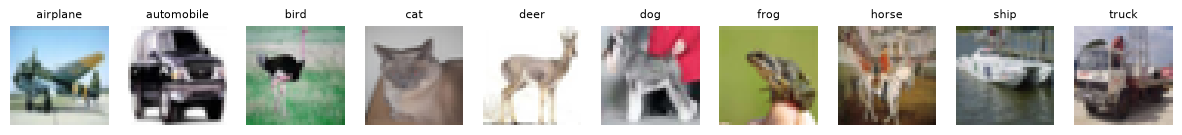

In [66]:
train_targets = torch.tensor(full_train.targets)
test_targets = torch.tensor(full_test.targets)
for name, t in [("train", train_targets[train_idx]), ("val", train_targets[val_idx]), ("test", test_targets[test_idx])]:
    print(name, torch.bincount(t, minlength=10).tolist())

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c in range(10):
    i = next(i for i in train_idx if full_train.targets[i] == c)
    axes[c].imshow(full_train[i][0].permute(1, 2, 0))
    axes[c].set_title(classes[c], fontsize=8)
    axes[c].axis("off")
plt.show()

#### Your answers: dataset

- `[3, 32, 32]` is 3 color channels (RGB) and a 32×32 image. FashionMNIST is `[1, 28, 28]`, so only one gray channel and smaller.
- 200 of 8200 images, so about 2.4%.
- If we look at the test set while choosing things, our test score is not honest anymore. It has to stay "new" data to show how the model works in real life.

## 2. Design your CNN

You design one CNN architecture and train it twice:
- Model A: your CNN without Dropout.
- Model B: exactly the same CNN with Dropout added. Nothing else changes.

Rules for your CNN:

| Rule | Requirement |
|---|---|
| Written by you | Build it from PyTorch layers: `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, `nn.Flatten`, `nn.Linear`, `nn.Dropout`. Not allowed: `torchvision.models`, `timm`, pretrained weights, or a network copied from a tutorial. |
| Depth | 5 to 10 layers with weights. Count `Conv2d` and `Linear` layers together. ReLU, MaxPool, Flatten and Dropout have no weights, so they do not count. |
| Convolution | At least 3 `Conv2d` layers, each followed by `ReLU`. |
| Pooling | At least 2 `MaxPool2d` layers. |
| Classifier head | `Flatten`, then at least one hidden `Linear` layer with `ReLU`, then `Linear(…, 10)`. |
| Output | 10 logits. No softmax inside the model: `nn.CrossEntropyLoss` applies it for you. |

`nn.BatchNorm2d` is allowed if you can explain what it does, but it is not required.

An example that follows the rules (6 layers with weights). You may use it or design your own:

- Block 1: `Conv2d(3, 32, kernel_size=3, padding=1) → ReLU → Conv2d(32, 32, kernel_size=3, padding=1) → ReLU → MaxPool2d(2)`
- Block 2: `Conv2d(32, 64, kernel_size=3, padding=1) → ReLU → Conv2d(64, 64, kernel_size=3, padding=1) → ReLU → MaxPool2d(2)`
- Head: `Flatten → Linear(?, 256) → ReLU → Linear(256, 10)`

Finding the number in place of `?` for your own CNN is part of the task.

Dropout for Model B:
- Required: `nn.Dropout(p=0.5)` right after the hidden `ReLU`, before the output `Linear`.
- Recommended: also `nn.Dropout(p=0.25)` right after `Flatten`.
- You may try other places or values of `p`, but choose using the validation set and write down what you tried.

In [67]:
def make_cnn(use_dropout):
    head = [nn.Flatten()]
    if use_dropout:
        head.append(nn.Dropout(0.25))
    head += [nn.Linear(64 * 8 * 8, 256), nn.ReLU()]
    if use_dropout:
        head.append(nn.Dropout(0.5))
    head.append(nn.Linear(256, 10))
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
        nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
        nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),
        *head,
    )

In [68]:
model_a, model_b = make_cnn(False), make_cnn(True)
x = torch.stack([train_set[i][0] for i in range(4)])
print(model_a(x).shape, model_b(x).shape)

out = x
for layer in model_b:
    out = layer(out)
    print(layer.__class__.__name__, tuple(out.shape))

print("layers with weights:", sum(isinstance(l, (nn.Conv2d, nn.Linear)) for l in model_a))
print("conv layers:", sum(isinstance(l, nn.Conv2d) for l in model_a))
print("pool layers:", sum(isinstance(l, nn.MaxPool2d) for l in model_a))

def count(model, kind=(nn.Conv2d, nn.Linear)):
    return sum(p.numel() for l in model if isinstance(l, kind) for p in l.parameters())

for name, m in [("A", model_a), ("B", model_b)]:
    print(name, "total:", count(m), "conv:", count(m, nn.Conv2d), "linear:", count(m, nn.Linear))

torch.Size([4, 10]) torch.Size([4, 10])
Conv2d (4, 32, 32, 32)
ReLU (4, 32, 32, 32)
Conv2d (4, 32, 32, 32)
ReLU (4, 32, 32, 32)
MaxPool2d (4, 32, 16, 16)
Conv2d (4, 64, 16, 16)
ReLU (4, 64, 16, 16)
Conv2d (4, 64, 16, 16)
ReLU (4, 64, 16, 16)
MaxPool2d (4, 64, 8, 8)
Flatten (4, 4096)
Dropout (4, 4096)
Linear (4, 256)
ReLU (4, 256)
Dropout (4, 256)
Linear (4, 10)
layers with weights: 6
conv layers: 4
pool layers: 2
A total: 1116970 conv: 65568 linear: 1051402
B total: 1116970 conv: 65568 linear: 1051402


#### Your answers: your CNN

- Conv(3→32) [32,32,32] → ReLU → Conv(32→32) [32,32,32] → ReLU → MaxPool [32,16,16] → Conv(32→64) [64,16,16] → ReLU → Conv(64→64) [64,16,16] → ReLU → MaxPool [64,8,8] → Flatten [4096] → Linear [256] → ReLU → Linear [10]. 6 layers with weights (4 conv + 2 linear).
- We put 4096 = 64·8·8. Conv with padding=1 keeps the size, each MaxPool halves it: 32 → 32 → 32 → 16 → 16 → 16 → 8.
- Total 1,116,970: conv 65,568, linear 1,051,402. By hand for the first conv: 3·32·3·3 + 32 = 896, same as in code.
- A 3×3 filter only looks at a small patch and the same weights are reused all over the image, so the count doesn't depend on image size. Almost all parameters sit in the first Linear (4096·256).
- Dropout has no weights, it just zeros values, so A and B are the same. No softmax because CrossEntropyLoss already does it inside on the logits.

## 3. Training setup

Use these settings for both models (you may change them, but write down what you used):

| Setting | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Batch size | 64 |
| Epochs | 15 |

Keep the seed, optimizer, learning rate, batch size and number of epochs the same for both models. Only Dropout changes, so the comparison is fair. We use 15 epochs so that overfitting has time to show up.

In [69]:
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=64)
test_loader = DataLoader(test_set, batch_size=64)
loss_fn = nn.CrossEntropyLoss()

#### Your prediction (write it before training)

- Model B, because Dropout should stop it from memorizing the train images.
- Model A will overfit more: its val loss will start going up after a few epochs. With Dropout the gap between train and val loss should be smaller.
- Cat and dog, because they are rare and look similar to each other.

## 4. Training and evaluation code

You can reuse `train_one_epoch` and `evaluate` from SIS 1. Changes: move every batch to your device (`images.to(device)`, `labels.to(device)`), move each model to the device after you build it, and switch between train and eval mode correctly, because Dropout depends on it.

Key words:
- Overfitting: the training loss keeps going down, but the validation loss stops improving or goes up. The model memorises the training images instead of learning patterns that also work on new images.
- Regularization: any method that reduces overfitting. Dropout is one of them.
- Dropout with probability `p`: during training, every value that enters the Dropout layer is set to zero with probability `p`, independently for every image and every step. The network cannot rely on one single neuron, so it learns features that still work when some neurons are missing (Goodfellow et al., *Deep Learning*, Section 7.12).
- Inverted dropout: during training, PyTorch multiplies the values that are kept by `1 / (1 − p)`. Because of this, the average value is the same in training and in evaluation, and nothing needs to be rescaled at test time.
- `model.train()` and `model.eval()`: Dropout is active only in train mode. In eval mode it passes values through unchanged. So `train_one_epoch` must call `model.train()` and `evaluate` must call `model.eval()`. Forgetting this is one of the most common bugs with Dropout.

In [70]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(images), labels)
        loss.backward()
        optimizer.step()

In [71]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            out = model(images)
            total_loss += loss_fn(out, labels).item() * len(labels)
            correct += (out.argmax(1) == labels).sum().item()
            n += len(labels)
    return total_loss / n, correct / n

In [72]:
def run_experiment(model, epochs=15):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    train_losses, val_losses = [], []
    for epoch in range(epochs):
        train_one_epoch(model, train_loader, loss_fn, optimizer)
        train_loss, _ = evaluate(model, train_loader, loss_fn)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        print(f"epoch {epoch + 1}: train loss {train_loss:.3f}, val loss {val_loss:.3f}, val acc {val_acc:.3f}")
    return train_losses, val_losses

## 5. Train both models

In [73]:
torch.manual_seed(42)
model_a = make_cnn(False).to(device)
train_a, val_a = run_experiment(model_a)

epoch 1: train loss 1.633, val loss 1.657, val acc 0.388
epoch 2: train loss 1.368, val loss 1.414, val acc 0.484
epoch 3: train loss 1.183, val loss 1.263, val acc 0.551
epoch 4: train loss 1.042, val loss 1.175, val acc 0.574
epoch 5: train loss 0.952, val loss 1.147, val acc 0.598
epoch 6: train loss 0.792, val loss 1.060, val acc 0.627
epoch 7: train loss 0.731, val loss 1.112, val acc 0.614
epoch 8: train loss 0.580, val loss 1.135, val acc 0.642
epoch 9: train loss 0.435, val loss 1.117, val acc 0.660
epoch 10: train loss 0.292, val loss 1.150, val acc 0.655
epoch 11: train loss 0.224, val loss 1.278, val acc 0.658
epoch 12: train loss 0.176, val loss 1.454, val acc 0.648
epoch 13: train loss 0.140, val loss 1.587, val acc 0.635
epoch 14: train loss 0.133, val loss 1.722, val acc 0.640
epoch 15: train loss 0.050, val loss 1.942, val acc 0.657


In [74]:
torch.manual_seed(42)
model_b = make_cnn(True).to(device)
train_b, val_b = run_experiment(model_b)

epoch 1: train loss 1.695, val loss 1.716, val acc 0.383
epoch 2: train loss 1.438, val loss 1.468, val acc 0.464
epoch 3: train loss 1.357, val loss 1.410, val acc 0.490
epoch 4: train loss 1.241, val loss 1.304, val acc 0.535
epoch 5: train loss 1.095, val loss 1.196, val acc 0.568
epoch 6: train loss 1.000, val loss 1.136, val acc 0.598
epoch 7: train loss 0.939, val loss 1.098, val acc 0.618
epoch 8: train loss 0.844, val loss 1.047, val acc 0.623
epoch 9: train loss 0.763, val loss 1.002, val acc 0.654
epoch 10: train loss 0.727, val loss 1.020, val acc 0.651
epoch 11: train loss 0.609, val loss 0.961, val acc 0.679
epoch 12: train loss 0.544, val loss 0.904, val acc 0.690
epoch 13: train loss 0.578, val loss 1.033, val acc 0.667
epoch 14: train loss 0.404, val loss 0.898, val acc 0.705
epoch 15: train loss 0.349, val loss 0.905, val acc 0.708


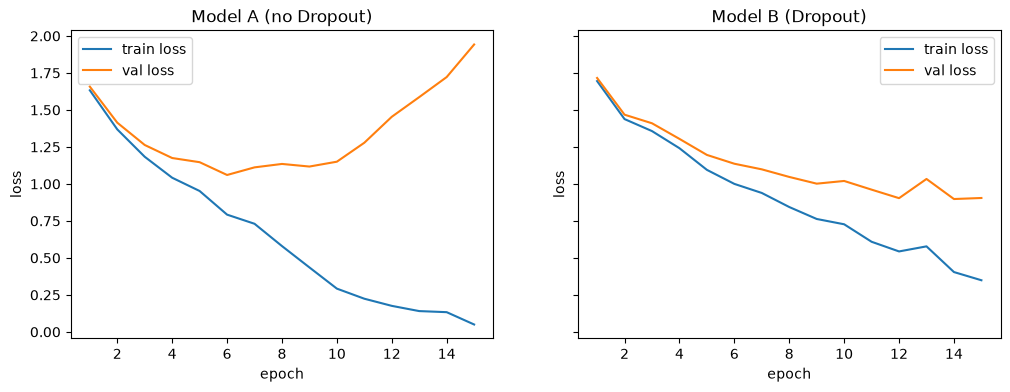

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, tr, va) in zip(axes, [("Model A (no Dropout)", train_a, val_a), ("Model B (Dropout)", train_b, val_b)]):
    epochs = range(1, len(tr) + 1)
    ax.plot(epochs, tr, label="train loss")
    ax.plot(epochs, va, label="val loss")
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.legend()
plt.show()

In [76]:
def accuracy_train_mode(model, loader):
    model.train()
    correct = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(1) == labels).sum().item()
    return correct / len(loader.dataset)

print("eval mode:", round(evaluate(model_b, val_loader, loss_fn)[1], 4))
print("train mode, run 1:", round(accuracy_train_mode(model_b, val_loader), 4))
print("train mode, run 2:", round(accuracy_train_mode(model_b, val_loader), 4))
model_b.eval()

eval mode: 0.7083
train mode, run 1: 0.6534
train mode, run 2: 0.6605


Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU()
  (7): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU()
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Dropout(p=0.25, inplace=False)
  (12): Linear(in_features=4096, out_features=256, bias=True)
  (13): ReLU()
  (14): Dropout(p=0.5, inplace=False)
  (15): Linear(in_features=256, out_features=10, bias=True)
)

#### Your answers: loss curves and Dropout

- Model A: train loss ___, val loss ___. Model B: train loss ___, val loss ___. Lower val loss: ___.
- Model A starts to overfit around epoch ___, val loss goes up while train loss keeps going down. Gap at the last epoch: A ___ vs B ___, so Dropout made the gap much smaller.
- Eval ___, train mode ___ and ___. In train mode part of the neurons are randomly turned off (p=0.25 and 0.5) so predictions are worse, and the mask is random each time so the numbers differ.
- During training Dropout is on and makes the model weaker, but validation is done in eval mode with the full network. So train loss can be higher, that's expected.
- ___ (yes / partly / no).

## 6. Metrics on the validation set

Before you touch the test set, you compute all metrics on the validation set and use them to choose your best model. Write the metric functions once: in section 8 you use the same functions on the test set.

Key words, part 1 (one predicted class per image):
- Confusion matrix: a 10 × 10 table. Row = true class, column = predicted class. Cell `[i, j]` counts images of class `i` that the model predicted as class `j`.
- Precision of a class: of all images the model called "cat", how many really are cats. `precision = TP / (TP + FP)`
- Recall of a class: of all real cats, how many the model found. `recall = TP / (TP + FN)`
- F1 of a class: `2 · precision · recall / (precision + recall)`. It is high only when both are high.
- Macro F1: the plain average of the 10 per-class F1 scores. Every class counts the same.
- Weighted F1: the average of the per-class F1 scores, weighted by how many images each class has. Big classes count more.

Here TP (true positive) = real cat predicted as cat, FP (false positive) = not a cat but predicted as cat, FN (false negative) = real cat predicted as something else.

Key words, part 2 (scores and ranking):
- Score for class `c`: the softmax probability `p(c | image)`. A higher score means the model is more sure the image belongs to class `c`.
- Precision-recall (PR) curve: sort all images by their score for class `c`, highest first. Call the top `k` images "predicted c" and compute precision and recall. Every `k` gives one point (recall, precision).
- precision@k: the share of real class-`c` images among the top `k`.
- Average precision (AP) of class `c`: the average of precision@k over the ranks `k` where a real class-`c` image appears. `AP = (precision@k₁ + precision@k₂ + … + precision@k_P) / P`, where `P` is the number of real class-`c` images and `k₁, …, k_P` are their ranks. AP = 1.0 when all class-`c` images are ranked above all other images. AP uses no threshold: it measures how well the model ranks the images.
- Random baseline: a model that gives random scores gets AP of about the share of class `c` in the data. For a rare class this baseline is very small.
- Macro AP (also called mAP, mean average precision): the plain average of the 10 per-class APs.

Worked example for AP. Five images, sorted by their cat score:

| Rank k | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Score for cat | 0.9 | 0.8 | 0.7 | 0.6 | 0.5 |
| Real cat? | yes | no | yes | no | no |
| precision@k | 1/1 | 1/2 | 2/3 | 2/4 | 2/5 |

The real cats are at ranks 1 and 3, so `AP = (1/1 + 2/3) / 2 = 0.833`. Your AP function must give 0.833 on this example.

In [77]:
def get_predictions(model, loader):
    model.eval()
    ys, probs = [], []
    with torch.no_grad():
        for images, labels in loader:
            probs.append(torch.softmax(model(images.to(device)), 1).cpu())
            ys.append(labels)
    probs = torch.cat(probs)
    return torch.cat(ys), probs.argmax(1), probs

In [78]:
def confusion_matrix(y_true, y_pred):
    cm = torch.zeros(10, 10, dtype=torch.long)
    for t, p in zip(y_true.tolist(), y_pred.tolist()):
        cm[t, p] += 1
    return cm

def metrics_from_cm(cm):
    tp = cm.diag().float()
    n_pred = cm.sum(0).float()
    n_true = cm.sum(1).float()
    precision = torch.where(n_pred > 0, tp / n_pred.clamp(min=1), torch.zeros(10))
    recall = tp / n_true
    f1 = torch.where(precision + recall > 0, 2 * precision * recall / (precision + recall + 1e-12), torch.zeros(10))
    acc = (tp.sum() / cm.sum()).item()
    macro_f1 = f1.mean().item()
    weighted_f1 = ((f1 * n_true).sum() / n_true.sum()).item()
    return precision, recall, f1, acc, macro_f1, weighted_f1

In [79]:
def average_precision(is_positive, scores):
    order = torch.argsort(scores, descending=True)
    pos = is_positive[order].float()
    precision_at_k = pos.cumsum(0) / torch.arange(1, len(pos) + 1)
    return ((precision_at_k * pos).sum() / pos.sum()).item()

print(round(average_precision(torch.tensor([1, 0, 1, 0, 0]), torch.tensor([0.9, 0.8, 0.7, 0.6, 0.5])), 3))

def all_ap(y_true, probs):
    aps = [average_precision(y_true == c, probs[:, c]) for c in range(10)]
    return aps, float(np.mean(aps))

0.833


In [80]:
def report(y_true, y_pred, probs):
    cm = confusion_matrix(y_true, y_pred)
    precision, recall, f1, acc, macro_f1, weighted_f1 = metrics_from_cm(cm)
    aps, macro_ap = all_ap(y_true, probs)
    print(f"{'class':<12}{'n':>6}{'prec':>8}{'rec':>8}{'f1':>8}{'ap':>8}")
    for c in range(10):
        print(f"{classes[c]:<12}{cm[c].sum().item():>6}{precision[c].item():>8.3f}{recall[c].item():>8.3f}{f1[c].item():>8.3f}{aps[c]:>8.3f}")
    print(f"accuracy {acc:.3f} | macro F1 {macro_f1:.3f} | weighted F1 {weighted_f1:.3f} | macro AP {macro_ap:.3f}")
    print(classification_report(y_true.numpy(), y_pred.numpy(), target_names=classes, digits=3, zero_division=0))
    sk_ap = np.mean([average_precision_score((y_true == c).numpy(), probs[:, c].numpy()) for c in range(10)])
    print("sklearn macro AP:", round(sk_ap, 3))
    return cm, macro_ap

val_preds = {"A": get_predictions(model_a, val_loader), "B": get_predictions(model_b, val_loader)}
val_ap = {}
for name, (y, p, pr) in val_preds.items():
    print("Model", name, "(validation)")
    _, val_ap[name] = report(y, p, pr)

Model A (validation)
class            n    prec     rec      f1      ap
airplane       500   0.659   0.650   0.655   0.712
automobile     500   0.777   0.642   0.703   0.787
bird           500   0.530   0.534   0.532   0.520
cat             50   0.083   0.020   0.032   0.042
deer           500   0.602   0.520   0.558   0.587
dog             50   0.280   0.140   0.187   0.131
frog           500   0.638   0.790   0.706   0.796
horse          500   0.669   0.740   0.703   0.800
ship           500   0.808   0.734   0.769   0.832
truck          500   0.637   0.758   0.692   0.756
accuracy 0.657 | macro F1 0.554 | weighted F1 0.651 | macro AP 0.596
              precision    recall  f1-score   support

    airplane      0.659     0.650     0.655       500
  automobile      0.777     0.642     0.703       500
        bird      0.530     0.534     0.532       500
         cat      0.083     0.020     0.032        50
        deer      0.602     0.520     0.558       500
         dog      0.280 

In [81]:
best_name = max(val_ap, key=val_ap.get)
best_model = model_a if best_name == "A" else model_b
print("best model:", best_name, "val macro AP:", round(val_ap[best_name], 3))

best model: B val macro AP: 0.651


#### Your answers: validation metrics

| Model | accuracy | macro F1 | weighted F1 | macro AP |
|---|---|---|---|---|
| A | ___ | ___ | ___ | ___ |
| B | ___ | ___ | ___ | ___ |

Best by macro AP: Model ___. Accuracy and macro F1 point to ___.
- Because the test set must stay untouched until the end, otherwise we basically tune on it and the final score is too optimistic.

## 7. Threshold search on the validation set

So far your prediction was argmax: the class with the highest probability wins. Now look at one rare class at a time as a yes/no question, "is this a cat?", and use a threshold `t`: predict cat if `p(cat) ≥ t`. A lower `t` gives more cat predictions: recall usually goes up and precision usually goes down. The threshold search finds a good balance. Use `best_model` and the validation set only.

Key words:
- Decision threshold `t`: the score from which we answer "yes, this is a cat".
- Operating point: one chosen `t` together with its precision and recall. It is one point on the PR curve.
- Why not simply `t = 0.5`? With 10 classes, the winning class often has a probability well below 0.5. So "`p(cat) ≥ 0.5`" can be much stricter than argmax. Check this in your numbers.

Choose two thresholds for cat and two for dog, on the validation set:

| Rule | How to choose `t` |
|---|---|
| Rule F1 | The `t` with the highest validation F1 for that class. Call it `t_F1`. |
| Rule R70 | The app team wants to find at least 70% of all cats (or dogs). Among the `t` with validation recall ≥ 0.70, take the one with the highest validation precision. Call it `t_R70`. If no `t` reaches 0.70, take the `t` with the highest recall and say so. |

Search over the grid `t = 0.01, 0.02, …, 0.99`.

In [82]:
def prf_at_threshold(is_positive, scores, t):
    pred = scores >= t
    tp = (pred & is_positive).sum().item()
    n_pred = pred.sum().item()
    precision = tp / n_pred if n_pred > 0 else 0
    recall = tp / is_positive.sum().item()
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
    return precision, recall, f1

grid = [round(0.01 * i, 2) for i in range(1, 100)]
y_val, _, probs_val = val_preds[best_name]
curves, thresholds = {}, {}
for c in (3, 5):
    rows = [prf_at_threshold(y_val == c, probs_val[:, c], t) for t in grid]
    curves[c] = rows
    i_f1 = max(range(len(grid)), key=lambda i: rows[i][2])
    ok = [i for i in range(len(grid)) if rows[i][1] >= 0.7]
    if ok:
        i_r70 = max(ok, key=lambda i: rows[i][0])
    else:
        i_r70 = max(range(len(grid)), key=lambda i: rows[i][1])
        print(classes[c], "never reaches recall 0.70, took the highest recall")
    thresholds[c] = {"t_F1": grid[i_f1], "t_R70": grid[i_r70]}
    for rule, i in [("t_F1", i_f1), ("t_R70", i_r70)]:
        p, r, f = rows[i]
        print(f"{classes[c]} {rule} = {grid[i]}: precision {p:.3f}, recall {r:.3f}, F1 {f:.3f}")

cat never reaches recall 0.70, took the highest recall
cat t_F1 = 0.09: precision 0.110, recall 0.200, F1 0.142
cat t_R70 = 0.01: precision 0.047, recall 0.680, F1 0.089
dog t_F1 = 0.06: precision 0.110, recall 0.380, F1 0.171
dog t_R70 = 0.01: precision 0.055, recall 0.760, F1 0.103


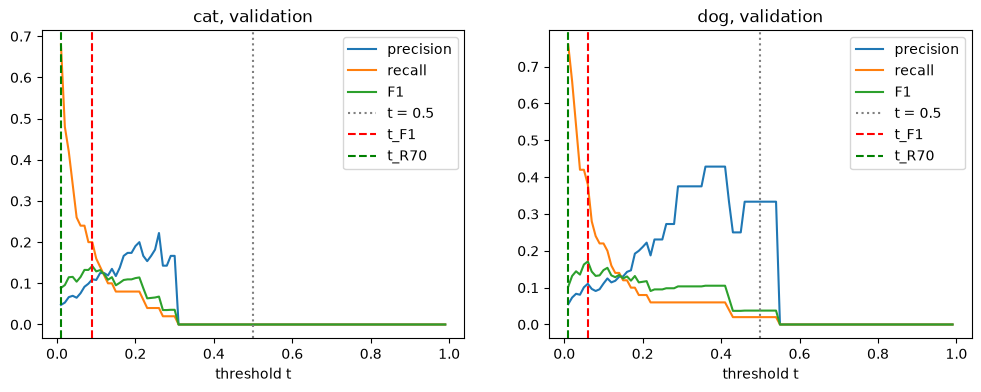

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, (3, 5)):
    rows = np.array(curves[c])
    ax.plot(grid, rows[:, 0], label="precision")
    ax.plot(grid, rows[:, 1], label="recall")
    ax.plot(grid, rows[:, 2], label="F1")
    ax.axvline(0.5, color="gray", linestyle=":", label="t = 0.5")
    ax.axvline(thresholds[c]["t_F1"], color="red", linestyle="--", label="t_F1")
    ax.axvline(thresholds[c]["t_R70"], color="green", linestyle="--", label="t_R70")
    ax.set_title(f"{classes[c]}, validation")
    ax.set_xlabel("threshold t")
    ax.legend()
plt.show()

#### Your answers: threshold search

- Cat: t_F1 = ___, t_R70 = ___. Dog: t_F1 = ___, t_R70 = ___. They are below 0.5, because with 10 classes argmax often wins with like 0.3-0.4, so 0.5 is too strict for a rare class.
- When t goes down we say "cat" more often, so recall goes up but more wrong images get in and precision drops. F1 peaks in the middle where both are still okay.
- There are 50 cats in val, so one more cat changes recall by 1/50 = 0.02. So the thresholds are not very exact, a small change can move them a lot.

## 8. Final evaluation on the test set

All decisions are made. Now use the test set, once. Do not change your models, your choice of `best_model` or your thresholds after this point. If you do, say so in your answers.

In [84]:
test_preds = {"A": get_predictions(model_a, test_loader), "B": get_predictions(model_b, test_loader)}
test_cm = {}
for name, (y, p, pr) in test_preds.items():
    print("Model", name, "(test)")
    test_cm[name], _ = report(y, p, pr)

Model A (test)
class            n    prec     rec      f1      ap
airplane      1000   0.657   0.648   0.653   0.721
automobile    1000   0.803   0.698   0.747   0.819
bird          1000   0.517   0.494   0.505   0.529
cat            100   0.045   0.010   0.016   0.045
deer          1000   0.574   0.475   0.520   0.578
dog            100   0.233   0.200   0.215   0.147
frog          1000   0.645   0.793   0.712   0.794
horse         1000   0.659   0.766   0.708   0.798
ship          1000   0.784   0.713   0.747   0.829
truck         1000   0.652   0.752   0.699   0.783
accuracy 0.654 | macro F1 0.552 | weighted F1 0.648 | macro AP 0.604
              precision    recall  f1-score   support

    airplane      0.657     0.648     0.653      1000
  automobile      0.803     0.698     0.747      1000
        bird      0.517     0.494     0.505      1000
         cat      0.045     0.010     0.016       100
        deer      0.574     0.475     0.520      1000
         dog      0.233     0.

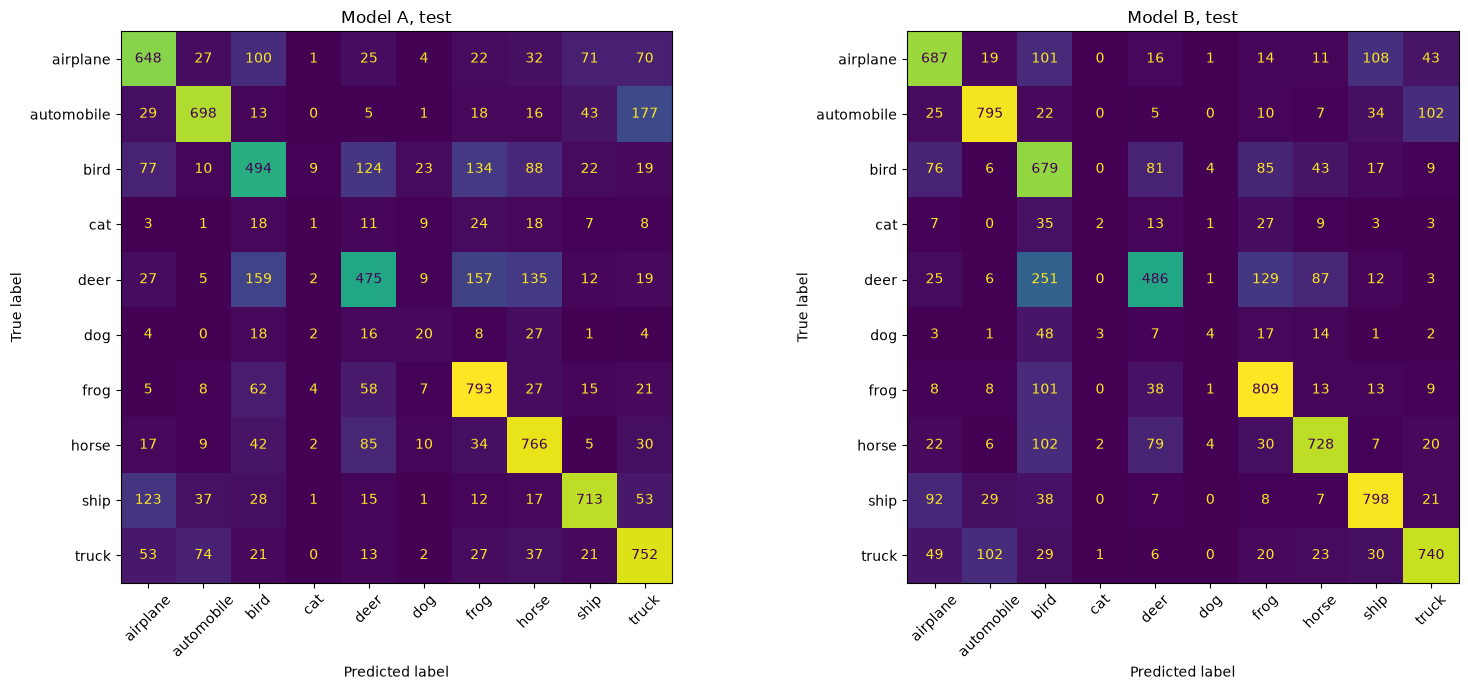

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, name in zip(axes, ["A", "B"]):
    ConfusionMatrixDisplay(test_cm[name].numpy(), display_labels=classes).plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(f"Model {name}, test")
plt.tight_layout()
plt.show()

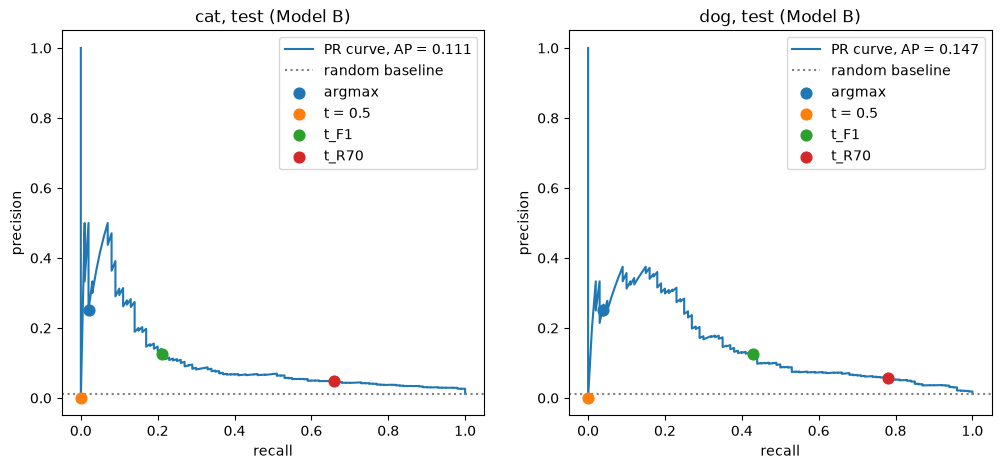

In [86]:
y_test, p_test, probs_test = test_preds[best_name]

def operating_points(c):
    is_pos = y_test == c
    pred = p_test == c
    tp = (pred & is_pos).sum().item()
    p = tp / pred.sum().item() if pred.sum() > 0 else 0
    r = tp / is_pos.sum().item()
    rows = [("argmax", "-", pred.sum().item(), p, r, 2 * p * r / (p + r) if p + r > 0 else 0)]
    for rule, t in [("t = 0.5", 0.5), ("t_F1", thresholds[c]["t_F1"]), ("t_R70", thresholds[c]["t_R70"])]:
        rows.append((rule, t, (probs_test[:, c] >= t).sum().item(), *prf_at_threshold(is_pos, probs_test[:, c], t)))
    return rows

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, c in zip(axes, (3, 5)):
    is_pos = y_test == c
    prec, rec, _ = precision_recall_curve(is_pos.numpy(), probs_test[:, c].numpy())
    ax.plot(rec, prec, label=f"PR curve, AP = {average_precision(is_pos, probs_test[:, c]):.3f}")
    ax.axhline(is_pos.float().mean().item(), color="gray", linestyle=":", label="random baseline")
    for rule, t, n, p, r, f in operating_points(c):
        ax.scatter(r, p, s=60, zorder=3, label=rule)
    ax.set_title(f"{classes[c]}, test (Model {best_name})")
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.legend()
plt.show()

In [87]:
for c in (3, 5):
    print(classes[c])
    print(f"{'rule':<10}{'t':>6}{'n pred':>8}{'prec':>8}{'rec':>8}{'f1':>8}")
    for rule, t, n, p, r, f in operating_points(c):
        print(f"{rule:<10}{str(t):>6}{n:>8}{p:>8.3f}{r:>8.3f}{f:>8.3f}")
    print()

cat
rule           t  n pred    prec     rec      f1
argmax         -       8   0.250   0.020   0.037
t = 0.5      0.5       0   0.000   0.000   0.000
t_F1        0.09     166   0.127   0.210   0.158
t_R70       0.01    1389   0.048   0.660   0.089

dog
rule           t  n pred    prec     rec      f1
argmax         -      16   0.250   0.040   0.069
t = 0.5      0.5       3   0.000   0.000   0.000
t_F1        0.06     346   0.124   0.430   0.193
t_R70       0.01    1385   0.056   0.780   0.105



#### Your answers: final metrics (explain properly)

1.

| Model | accuracy | macro F1 | weighted F1 | macro AP |
|---|---|---|---|---|
| A | ___ | ___ | ___ | ___ |
| B | ___ | ___ | ___ | ___ |

Weighted F1 is closer to accuracy because big classes dominate both, and cat/dog barely count there.

2. Precision: of ___ images predicted as cat, ___ were real cats, so ___/___ = ___. Recall: of 100 real cats we found ___, so recall = ___. F1 = ___, it's low because ___ is low. AP = ___, this is how well real cats are ranked by cat score, without any threshold.
3. Recall shows that we miss most cats and dogs (___ and ___), accuracy hides it since they are only 2.4% of the test set. A model that never predicts them would lose at most 2.4% accuracy, actually only ___% since it already gets few of them right.
4. Baseline AP: cat 100/8200 = 0.012, airplane 1000/8200 = 0.122. Our cat AP ___ is ~___ times better than random. The same AP means different things because the baseline depends on how common the class is.
5. AP looks at the whole ranking, so t doesn't matter, F1 depends on one chosen t. AP is good for comparing models, F1 at a threshold is what the app really gets.
6. R70 on test gave recall ___ (≥ / < 0.70). t_F1 gave the best test F1: ___. Differences happen because val only has 50 cats and 50 dogs, so the thresholds are noisy.
7. Model B vs A: macro F1 ___ vs ___, macro AP ___ vs ___, cat recall ___ vs ___, dog recall ___ vs ___. So Dropout ___.
8. Real cats are most often predicted as ___ and ___. Makes sense, these are animals with similar shape and colors, and the model saw way more of them in training.

## 10. Defense checklist and grading

Submit this completed notebook (or an HTML/PDF export with all cells and plots visible) before your defense. Each group has a short (~5 min) defense. Any member may be asked to:

- explain any line of your code: the subsets, every layer of your CNN, and the training steps
- show how the image shape changes through your CNN, and how you got the input size of the first `Linear` layer
- compute the number of parameters of one of your `Conv2d` layers by hand
- explain what Dropout does in train mode and in eval mode, and show the lines in your code where the mode is switched
- explain precision and recall for one class using a row and a column of your confusion matrix
- compute AP by hand for a short ranked list given by the instructor
- explain why the thresholds were chosen on the validation set and not on the test set, and what happens to precision and recall when `t` goes down
- explain why accuracy can look fine while the model fails on cats and dogs

The Week 7 SIS mini-project is worth 4 points:

| Criterion | Full credit requires | Points |
|---|---|---|
| 1. Your CNN and training | Code written by the group runs from top to bottom. The three subsets match the table. The CNN follows every rule in section 2 and is built from PyTorch layers, not a ready-made or pretrained network. Model A and Model B differ only by Dropout. `model.train()` and `model.eval()` are used correctly. Both models are trained with the same settings, and the loss curves of both are plotted with the same y-axis range, a title, axis labels and a legend. | 1 |
| 2. Metrics and threshold search | Confusion matrix, per-class precision, recall, F1 and AP are computed by your own functions and match scikit-learn. The AP function gives 0.833 on the worked example. The best model and all four thresholds are chosen on the validation set only. Plots: confusion matrices with class names, precision/recall/F1 against `t`, and test PR curves with the random baseline and the four operating points. | 1 |
| 3. Explanations | All answer cells are filled in, correct, short, and use your own numbers: Dropout and train vs eval mode, each metric explained for the cat class, AP vs F1 and the random baseline, the threshold trade-off, and how the thresholds worked on the test set. | 1 |
| 4. Oral defense | Each member individually explains the group's code, plots and metrics (checklist above). | 1 |
| Total | | 4 |

How points are given:
- Criteria 1 to 3 are the same for the whole group. Criterion 4 is given to each student separately.
- A criterion that is mostly met, with one listed part missing or wrong, gets 0.5.
- If the test set was used to choose the model or a threshold, criterion 2 gets at most 0.5.
- If the CNN is a ready-made or pretrained network, criterion 1 gets 0.

Optional (no extra points):
- Class weights: pass `weight=` to `nn.CrossEntropyLoss` so rare classes count more (for example 10 for cat and dog, 1 for the rest). Train Model B again. Did recall for cat and dog go up? What happened to accuracy and to the best thresholds?
- ROC-AUC vs AP: for "cat vs not cat" on the test set, compute ROC-AUC with `sklearn.metrics.roc_auc_score` and plot the ROC curve with `sklearn.metrics.RocCurveDisplay`. A random model gets ROC-AUC 0.5 but AP equal to the share of cats. Why does ROC-AUC look much better than AP for a rare class?
- Rare vs hard: cats and dogs are hard classes even in normal, balanced CIFAR-10. How could you check how much of their low recall comes from having few training images, and how much from the classes being hard?
- Thresholds inside the 10-class classifier: predict cat if `p(cat) ≥ t_F1`, otherwise use argmax. What happens to accuracy and to the recall of the other classes?